In [2]:
import pandas as pd
import paramiko
import matplotlib.pyplot as plt

In [3]:
wind_speed_data = pd.read_pickle("wind_speed_data.pkl")  # CSVファイルの読み込み

In [4]:
import numpy as np
import pandas as pd

# 高度リスト（リスト型なので .size ではなく len() を使います）
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]


def detect_llj(time_val, alt_list, df):
    """特定の時間（time_val）における風速プロファイルからLLJを判定する関数"""

    # 1. 指定された時間の行データを取得
    row = df[df["Timestamp (end of interval)"] == time_val]
    if row.empty:
        return "False", pd.NA

    # 2. 高度リストに対応する風速データを配列(NumPy)として抽出
    speed_columns = [f"{h}m Wind Speed (m/s)" for h in alt_list]
    wind_speeds = row[speed_columns].values.flatten().astype(float)

    n = len(wind_speeds)

    # 3. 高度方向にスキャン (インデックス i で回す)
    for i in range(1, n - 1):
        # 簡易的な極大値の判定 (前後のインデックスと比較)
        if wind_speeds[i] > wind_speeds[i - 1] and wind_speeds[i] >= wind_speeds[i + 1]:
            v_max = wind_speeds[i]
            z_max = alt_list[i]

            # --- 条件b), c) を考慮して、真の極小値 v_min を探索する ---
            v_min = None
            z_min = None

            # 極大値の次のインデックスから、上空（末尾）に向かってスキャン
            j = i + 1
            current_min_val = wind_speeds[j]
            current_min_idx = j

            while j < n:
                # 暫定の最小値を更新
                if wind_speeds[j] < current_min_val:
                    current_min_val = wind_speeds[j]
                    current_min_idx = j

                # 次の山（極大候補）が現れたかチェック
                if j < n - 1 and wind_speeds[j] < wind_speeds[j + 1]:
                    # 次の山のピークを探す
                    k = j
                    while k < n - 1 and wind_speeds[k] < wind_speeds[k + 1]:
                        k += 1
                    next_max_val = wind_speeds[k]

                    displacement = next_max_val - current_min_val

                    if displacement < 1.0:
                        # 変位が1m/s未満なら、この谷は無視してスキャン続行（次の極小へ）
                        j = k
                        continue
                    else:
                        # 変位が1m/s以上なら、ここを真の極小値として確定
                        v_min = current_min_val
                        z_min = alt_list[current_min_idx]
                        break
                j += 1

            # 条件c): スキャンが末尾（最大高度）に達しても極小値が確定しなかった場合
            if v_min is None:
                v_min = current_min_val
                z_min = alt_list[current_min_idx]

            # --- 条件a) の判定 ---
            diff = v_max - v_min
            ratio = diff / v_min

            if diff > 2.0 and ratio > 0.25:
                # すべての条件を満たした場合、LLJとして確定
                return "True", z_max

    # ループを抜けても見つからなかった場合
    return "False", pd.NA


# --- 一番外側のメインループ（Timestampを基準に回す） ---
llj_list = []
llj_alt = []

print("Timestampを基準にしたLLJループ処理を開始します...")

# DataFrameから一意の時間リストを取得してループを回す
unique_timestamps = wind_speed_data["Timestamp (end of interval)"].unique()

for current_time in unique_timestamps:
    # 関数を呼び出して判定結果を受け取る
    status, height = detect_llj(current_time, alt, wind_speed_data)

    # 結果をリストに追加
    llj_list.append(status)
    llj_alt.append(height)

# DataFrameに新しい列として追加して結果を確認
wind_speed_data["LLJ_Status"] = llj_list
wind_speed_data["LLJ_Height"] = llj_alt

print("処理完了！")
print("LLJ検出数:", (wind_speed_data["LLJ_Status"] == "True").sum(), "件")

Timestampを基準にしたLLJループ処理を開始します...
処理完了！
LLJ検出数: 58 件


LLJが発生している 58 件のデータをプロットします。


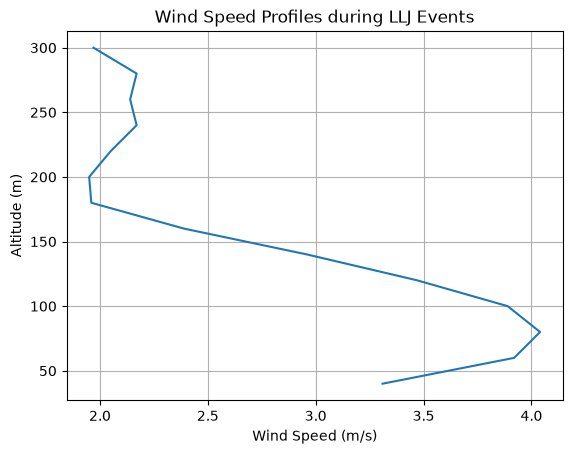

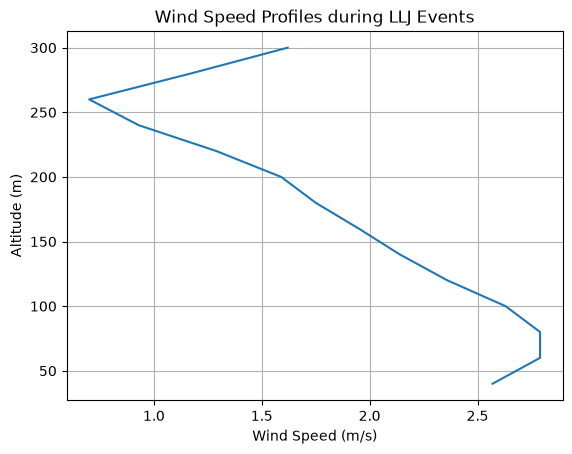

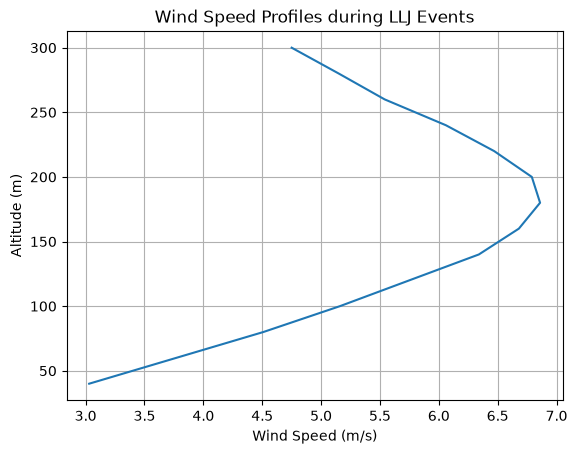

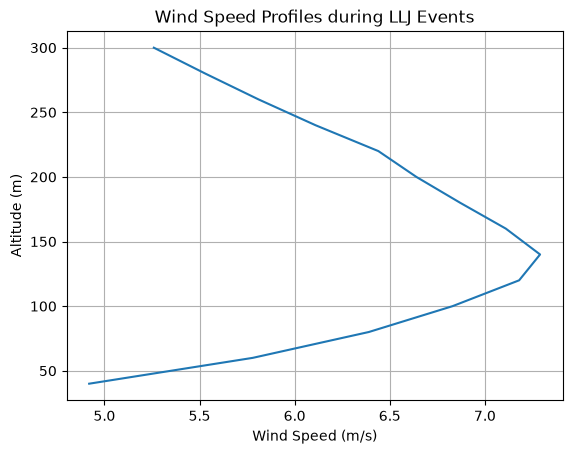

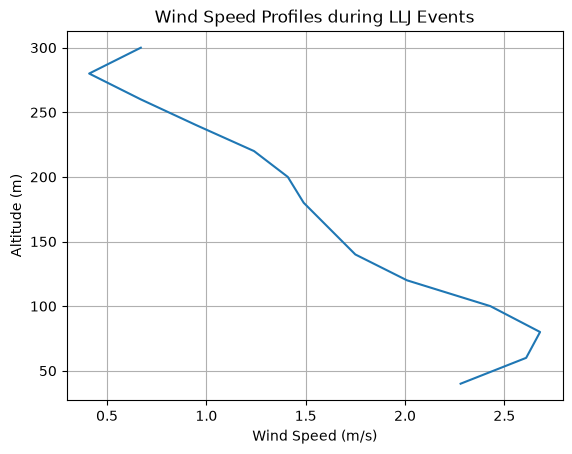

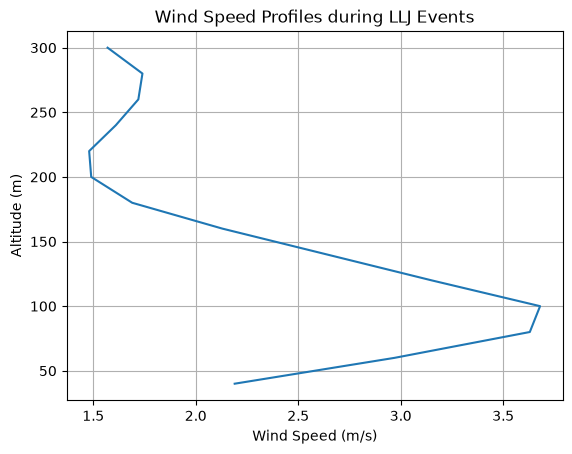

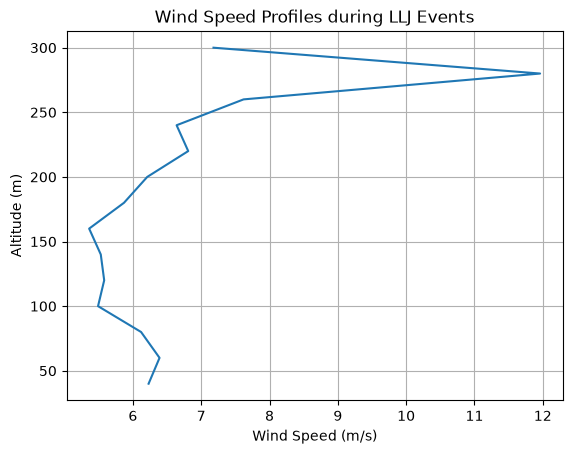

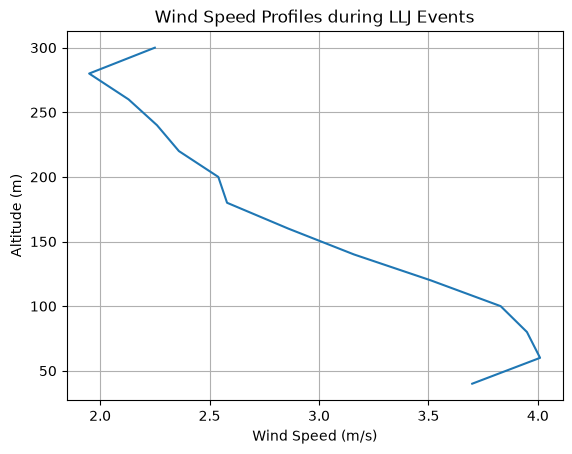

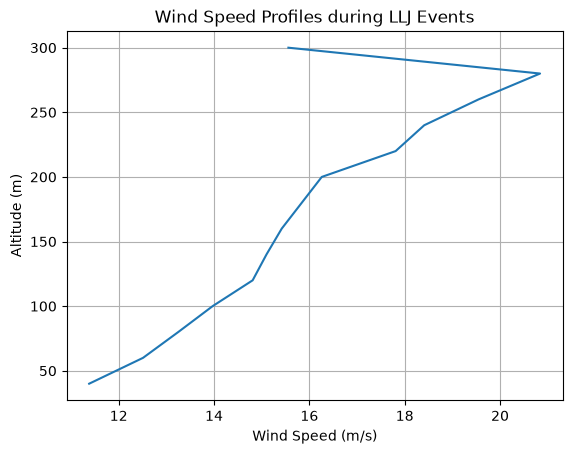

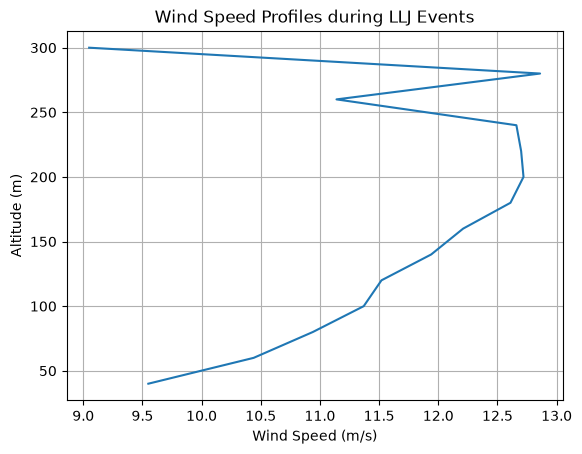

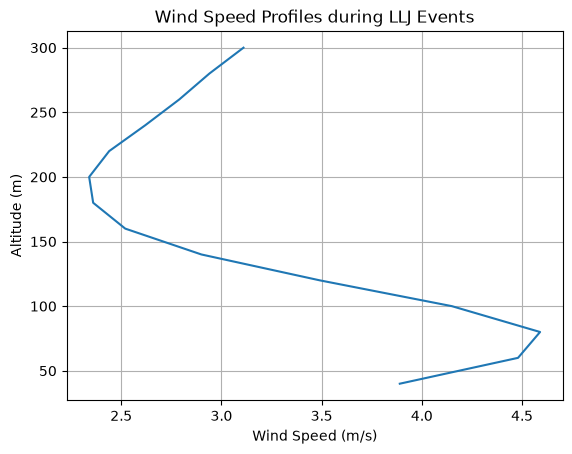

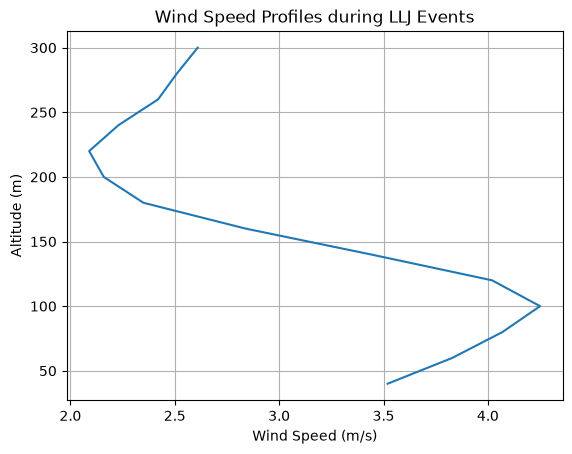

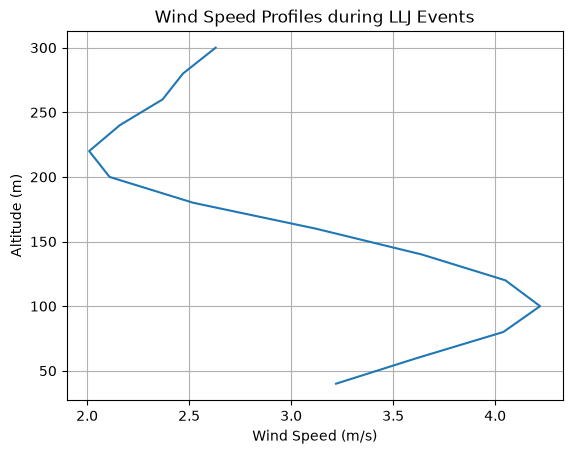

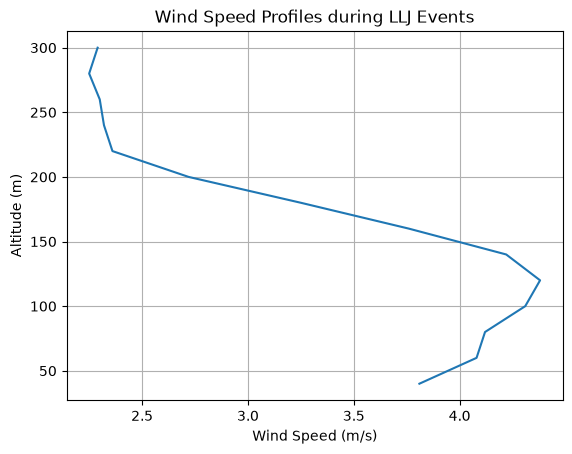

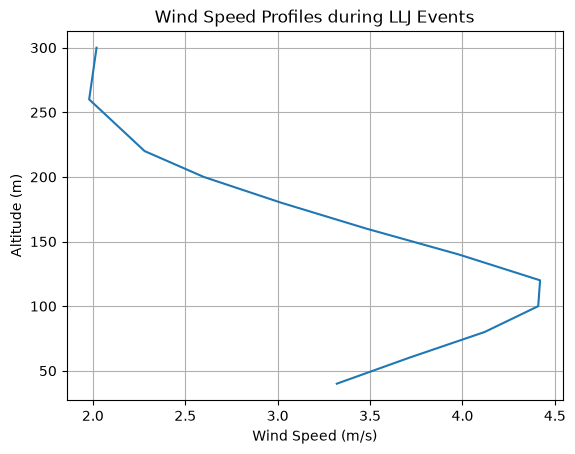

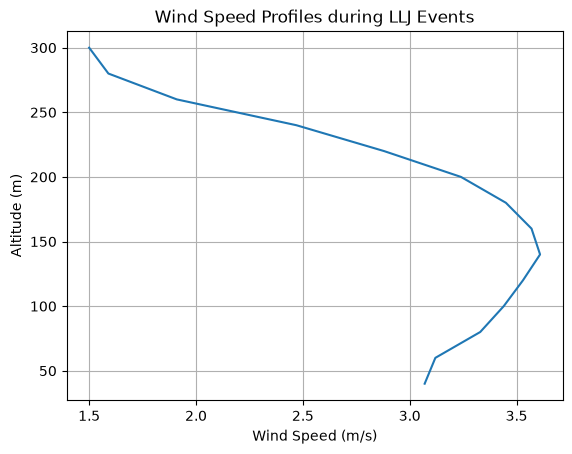

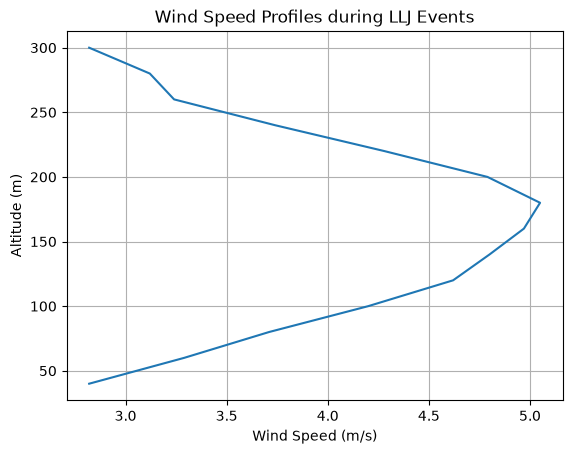

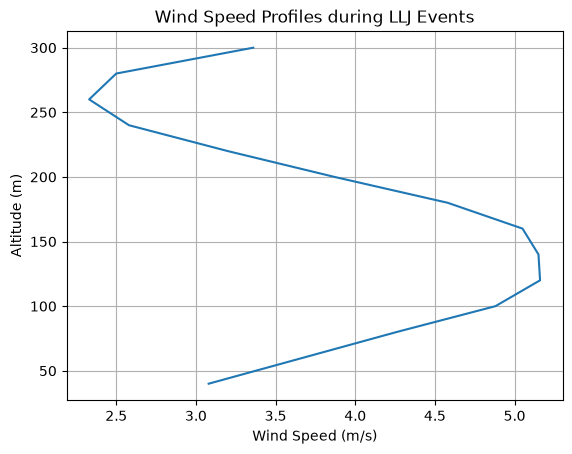

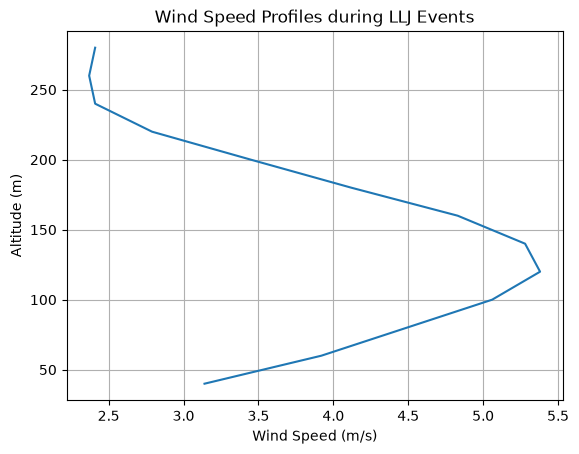

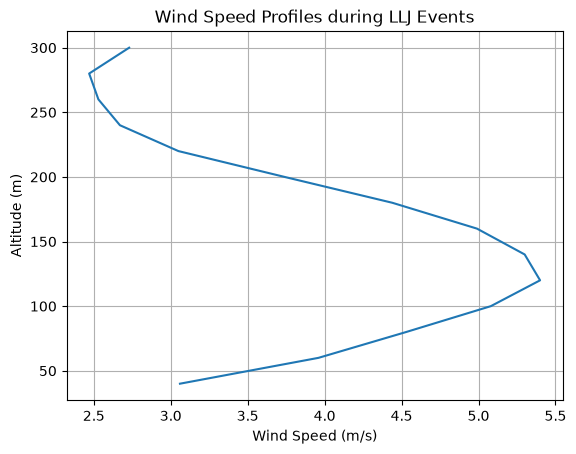

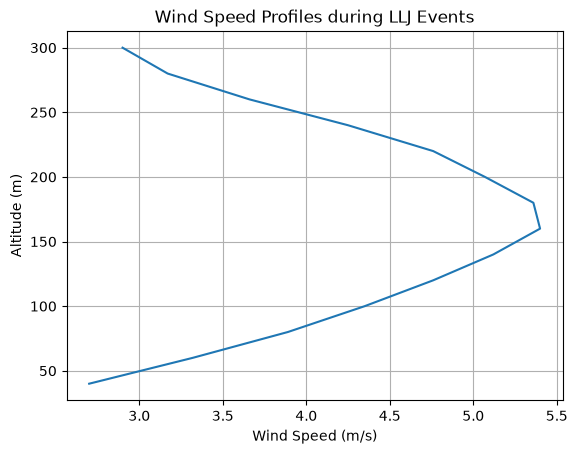

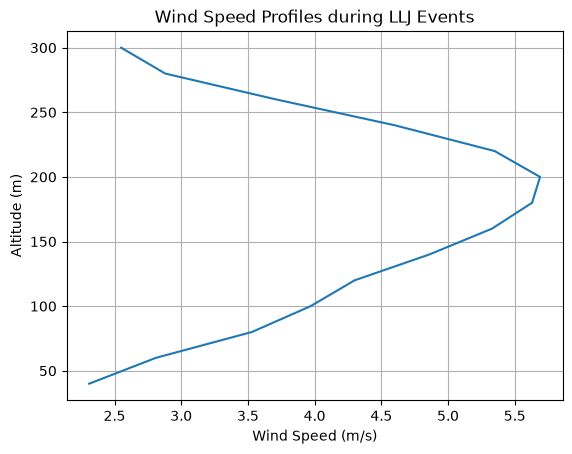

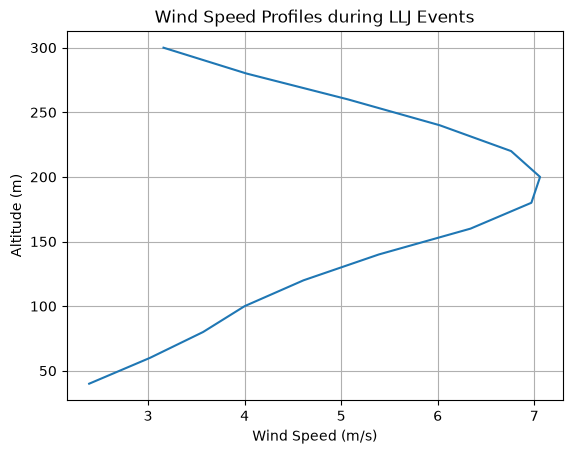

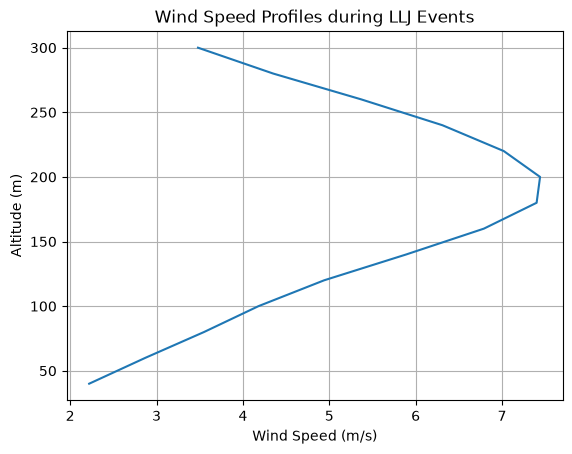

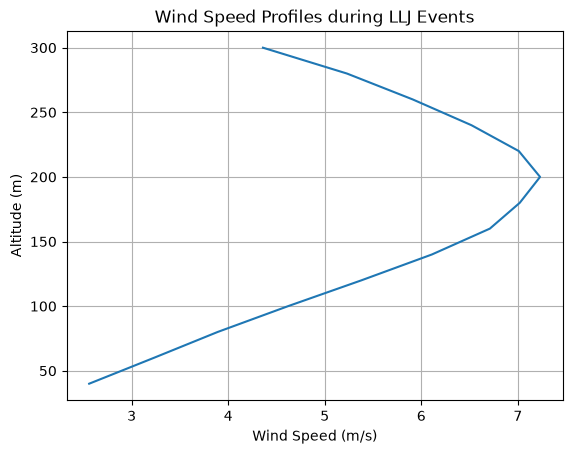

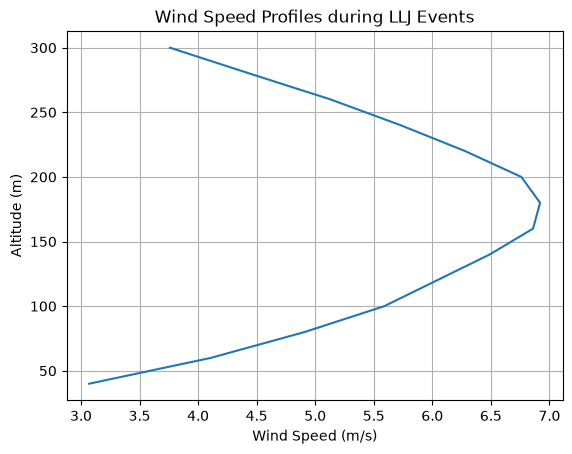

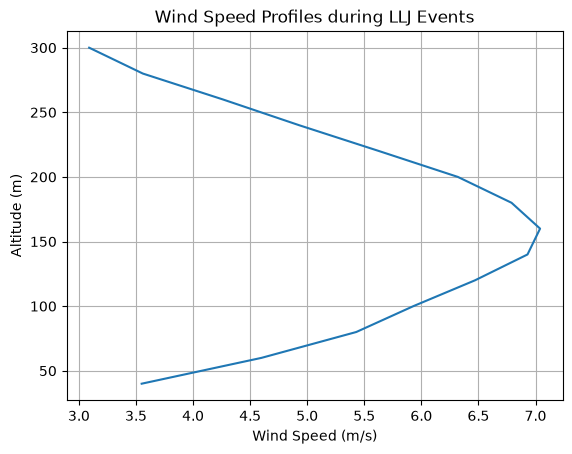

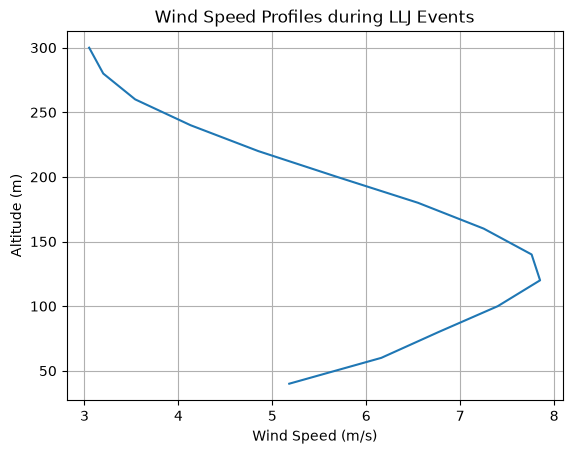

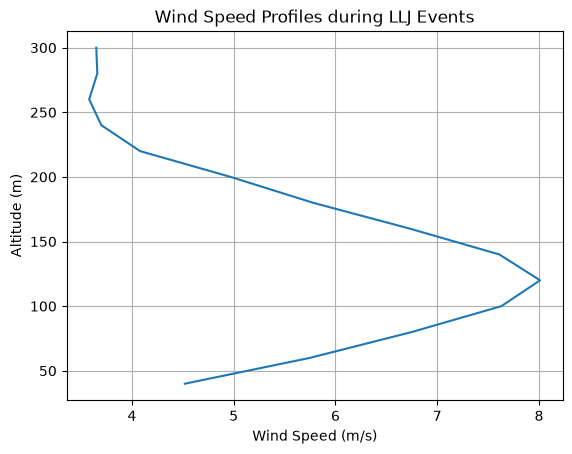

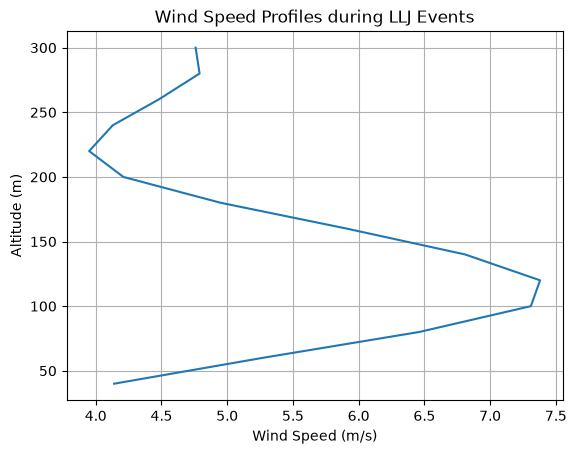

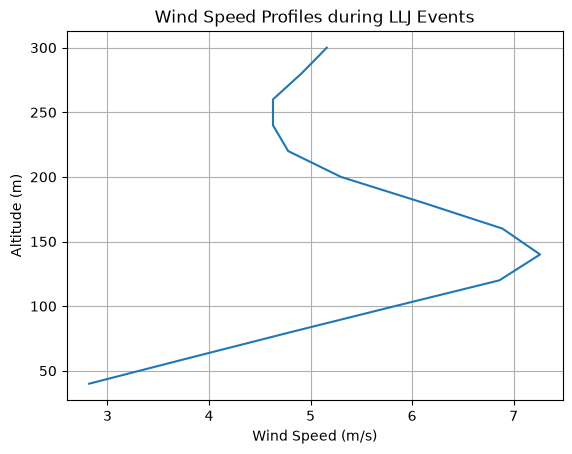

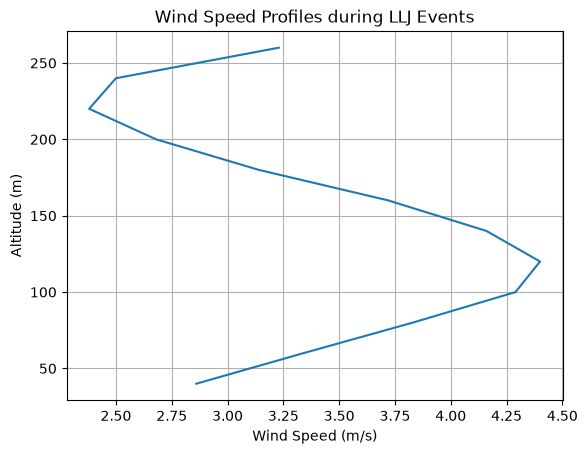

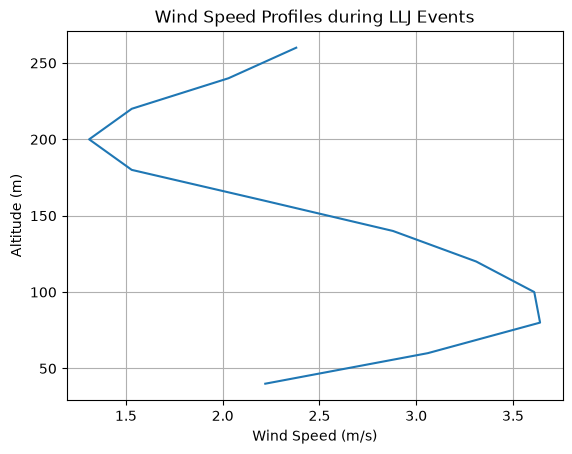

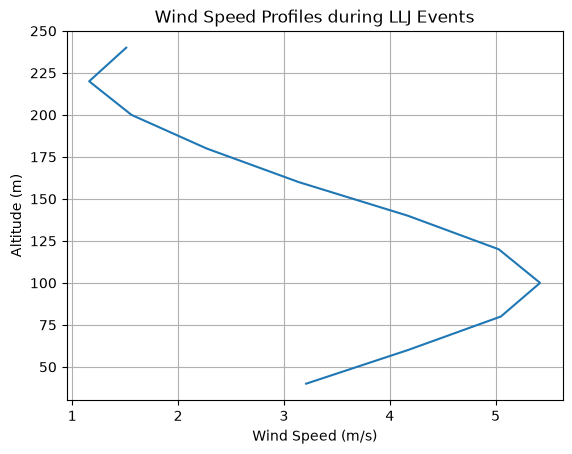

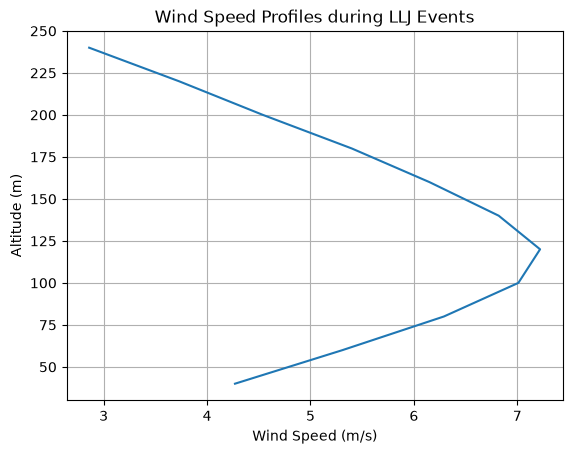

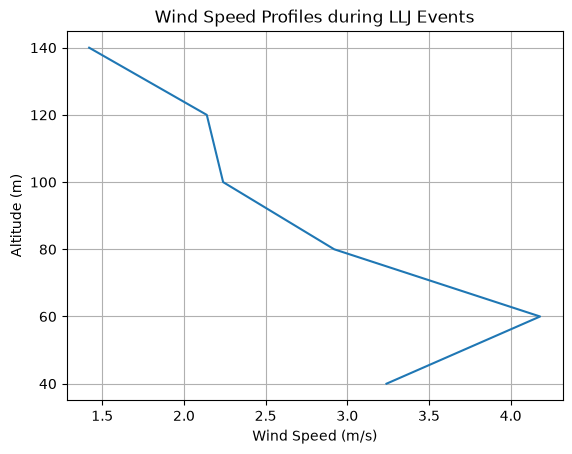

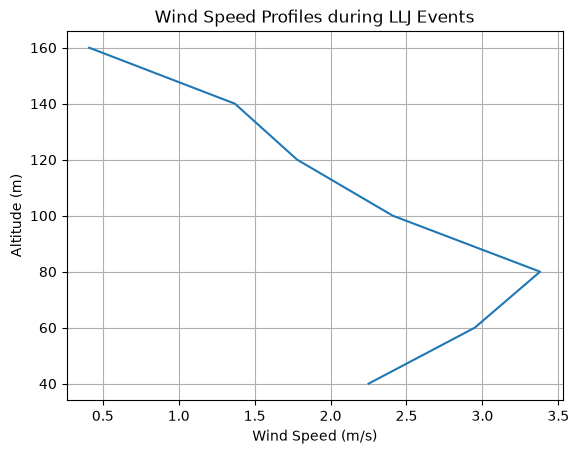

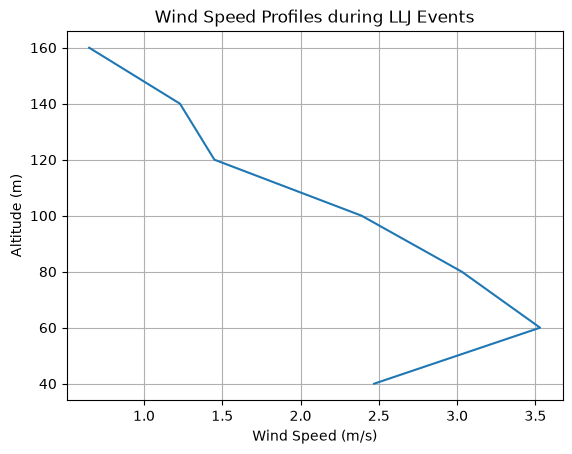

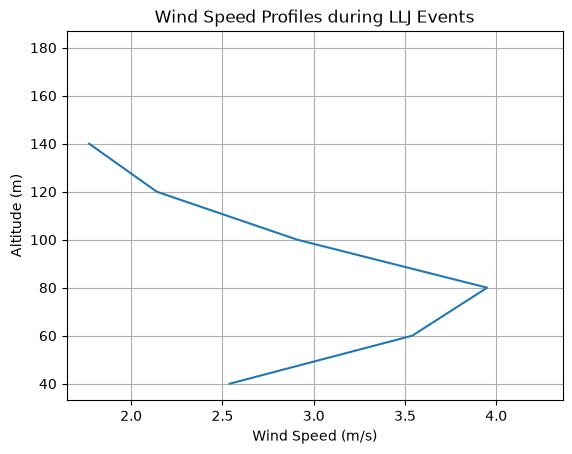

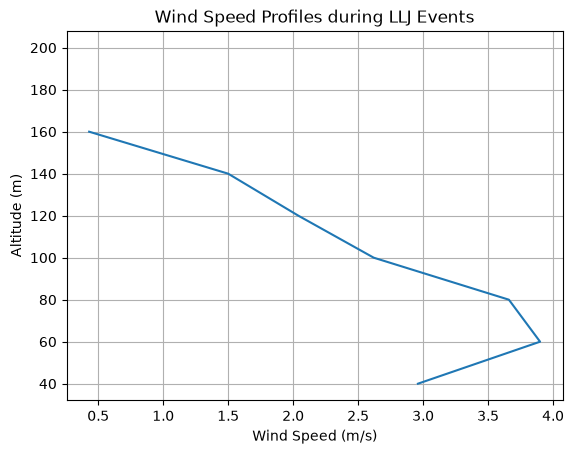

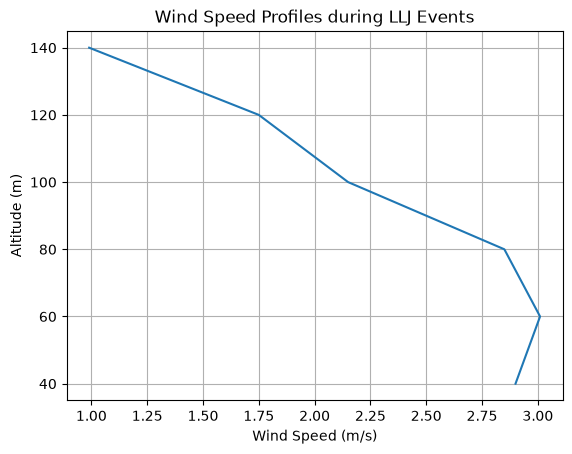

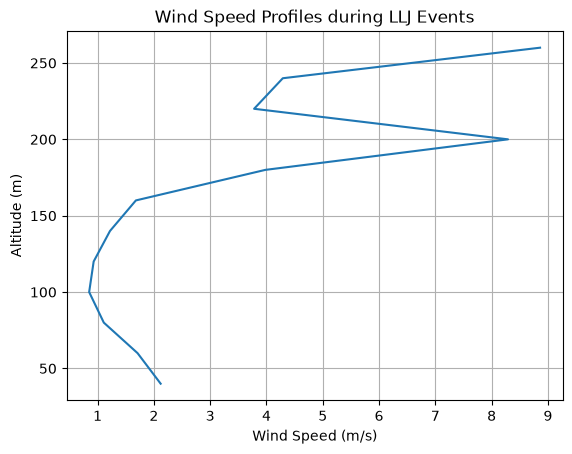

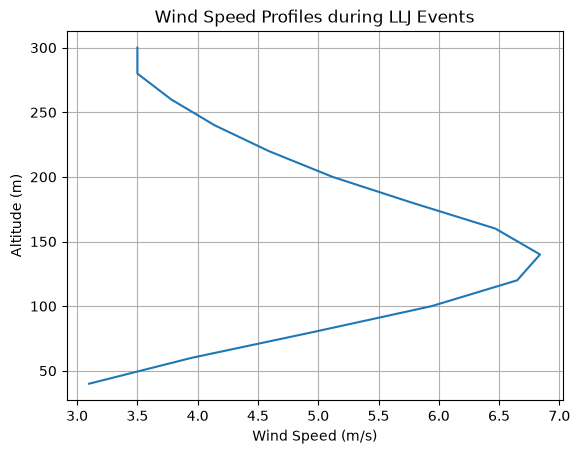

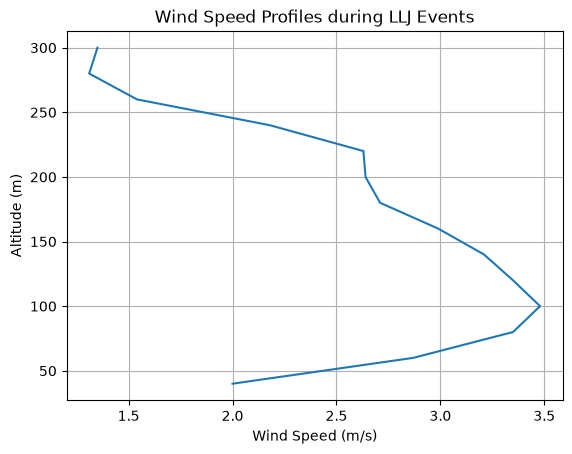

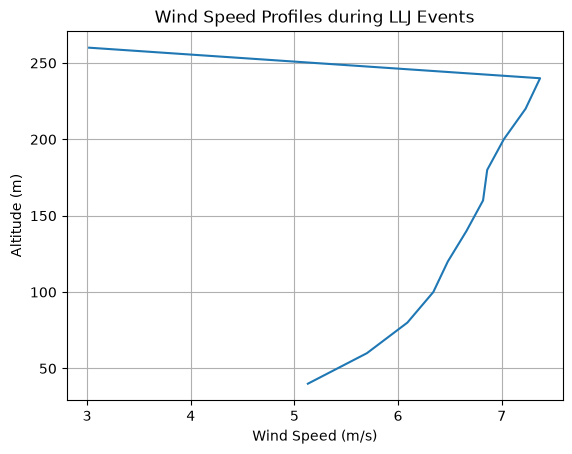

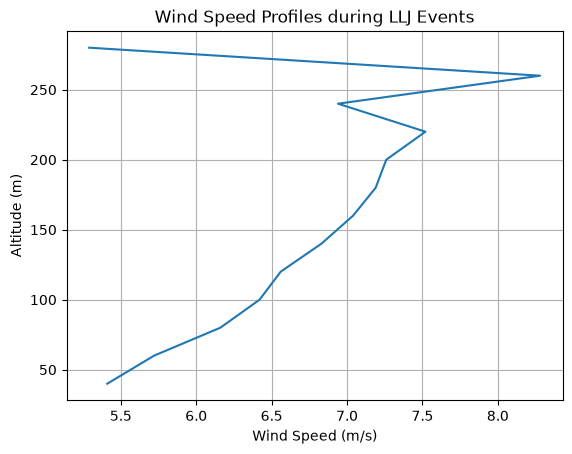

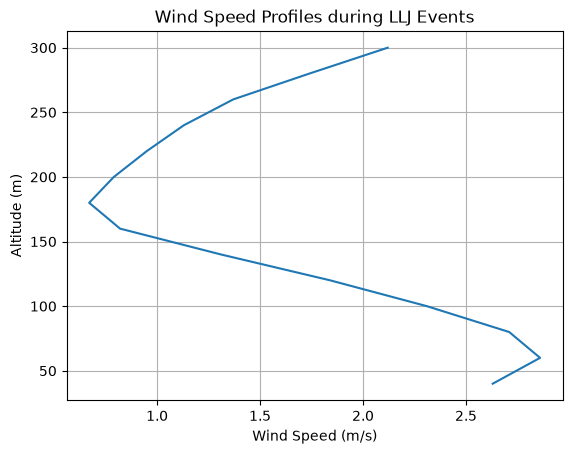

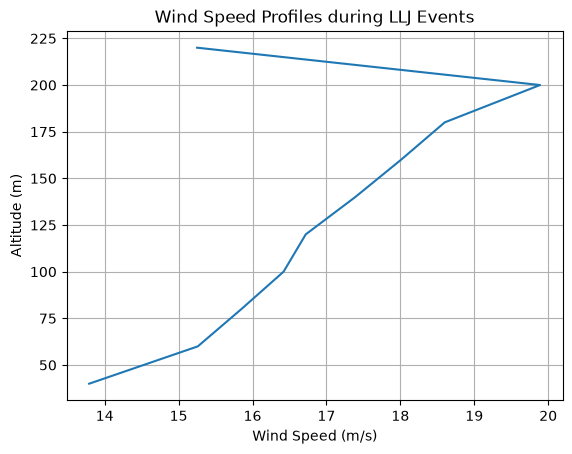

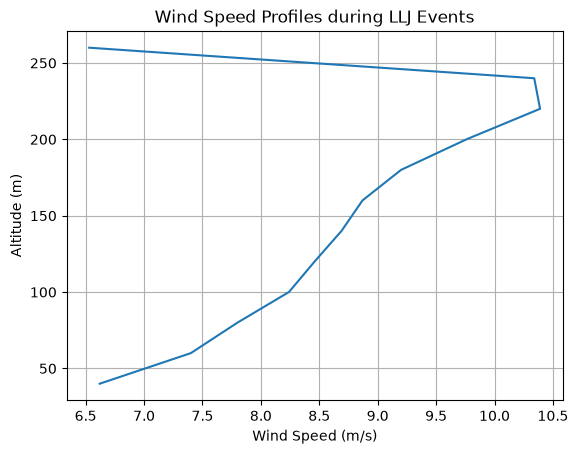

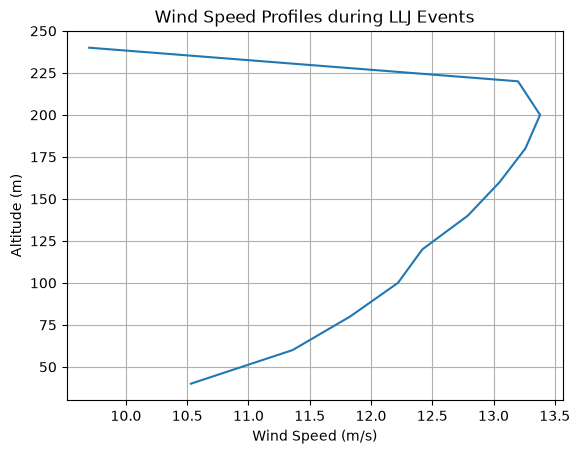

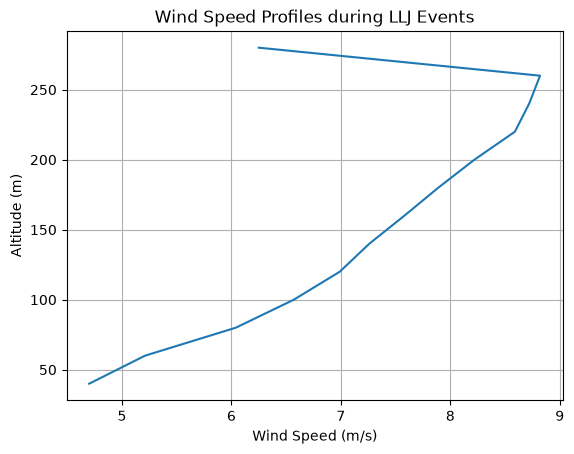

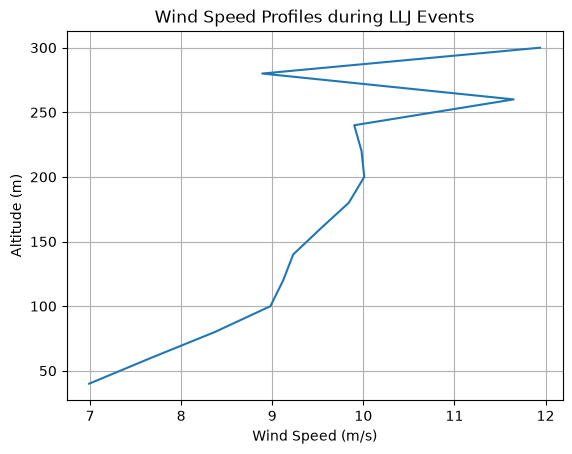

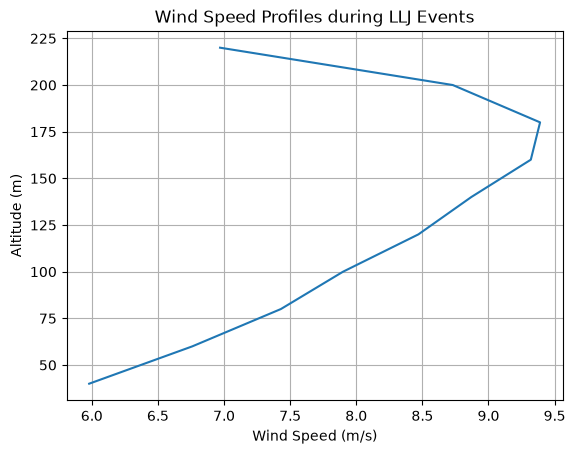

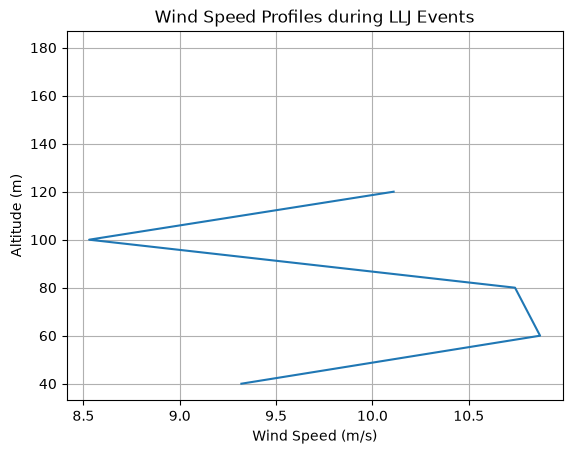

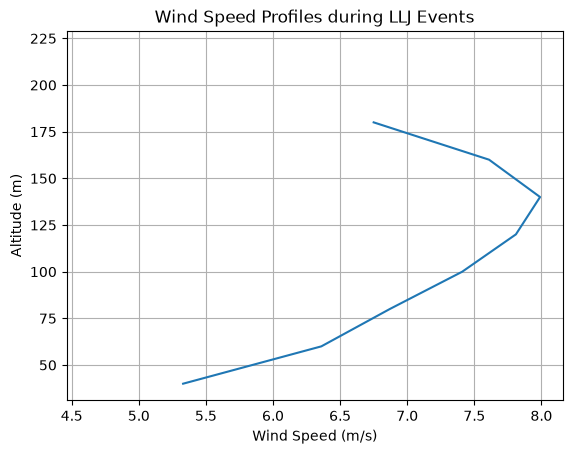

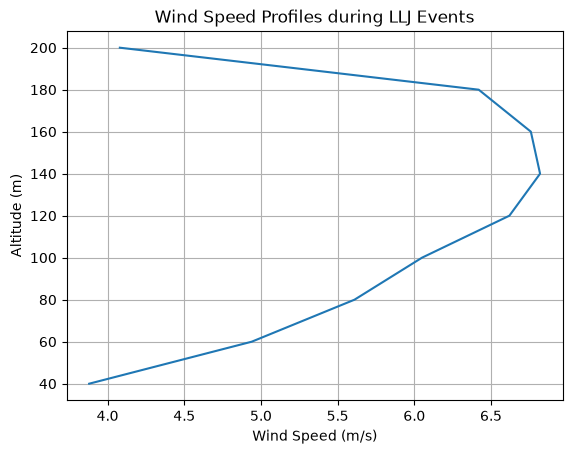

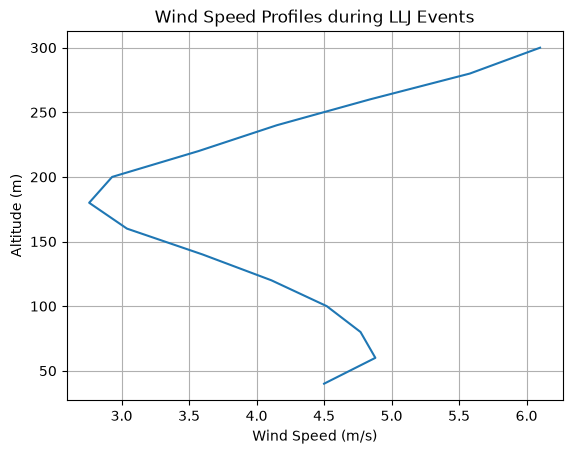

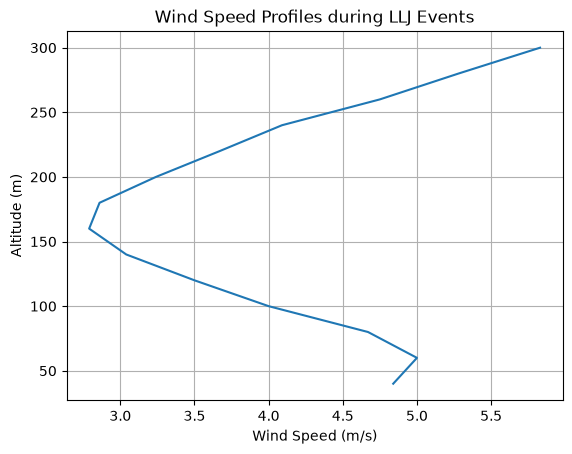

In [5]:
import matplotlib.pyplot as plt

# プロットに使用する高度リスト
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
speed_columns = [f"{h}m Wind Speed (m/s)" for h in alt]

# 1. LLJ_Status が "True" の行だけを絞り込む
df_llj_only = wind_speed_data[wind_speed_data["LLJ_Status"] == "True"]

print(f"LLJが発生している {len(df_llj_only)} 件のデータをプロットします。")

# 2. 絞り込んだデータに対して for ループを回す
for idx, row in df_llj_only.iterrows():
    current_time = row["Timestamp (end of interval)"]

    # その時間の風速データ（14個）だけを的確に抽出
    speeds = row[speed_columns].values.astype(float)

    # 散布図プロット（横軸：風速、縦軸：高度）
    plt.plot(speeds, alt, label=f"{current_time}")

# グラフの見た目を整える
    plt.xlabel("Wind Speed (m/s)")
    plt.ylabel("Altitude (m)")
    plt.title("Wind Speed Profiles during LLJ Events")
    plt.grid(True)

    # 件数が多いと凡例（Label）が画面を埋め尽くすので、必要に応じてコメントアウトを外してください
    # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.show()

In [6]:
wind_speed_data 

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height
0,2025-02-01 00:10:00,2.19,2.48,2.79,3.12,3.19,3.22,3.35,3.53,3.77,4.23,4.64,4.99,5.37,5.61,False,<NA>
1,2025-02-01 00:20:00,1.35,1.26,1.27,1.50,1.74,2.31,2.54,2.94,3.48,3.89,4.03,4.09,4.25,4.40,False,<NA>
2,2025-02-01 00:30:00,2.59,3.06,3.35,3.58,3.78,4.11,4.26,4.38,4.41,4.68,4.95,5.21,5.39,5.66,False,<NA>
3,2025-02-01 00:40:00,3.26,3.53,3.42,3.59,3.74,3.80,4.01,4.34,4.64,4.85,5.06,5.08,5.26,5.39,False,<NA>
4,2025-02-01 00:50:00,2.89,3.10,3.39,3.68,3.81,3.81,3.81,3.93,4.18,4.47,4.73,5.23,5.47,5.71,False,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3997,2025-02-28 23:20:00,3.68,4.17,4.48,4.75,5.12,5.23,5.21,5.34,5.47,5.74,5.93,5.90,6.09,6.45,False,<NA>
3998,2025-02-28 23:30:00,3.89,4.18,4.25,4.28,4.37,4.48,4.57,4.70,5.00,5.27,5.53,5.69,6.06,6.06,False,<NA>
3999,2025-02-28 23:40:00,2.93,3.28,3.46,3.68,3.94,4.12,4.46,4.65,4.84,5.18,5.54,5.77,5.96,6.14,False,<NA>
4000,2025-02-28 23:50:00,3.95,4.38,4.52,4.57,4.63,4.75,4.93,5.18,5.43,5.60,5.90,6.01,6.26,6.51,False,<NA>


In [7]:
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]

# データ全体の行数でループを回す（端データのエラーを防ぐため 1 から len-1 まで）
for i in range(1, len(wind_speed_data) - 1):

    # 元の時系列データのまま、i-1, i, i+1 の3箇所が連続して "True" かをチェック
    is_continuous_3or_more = (
        wind_speed_data["LLJ_Status"].iloc[i - 1] == "True"
        and wind_speed_data["LLJ_Status"].iloc[i] == "True"
        and wind_speed_data["LLJ_Status"].iloc[i + 1] == "True"
    )
    if pd.Timedelta(wind_speed_data["Timestamp (end of interval)"].iloc[i+1]-wind_speed_data["Timestamp (end of interval)"].iloc[i-1] ) < pd.Timedelta(minutes=31):
        if is_continuous_3or_more:
        # 条件を満たした場合、現在の行（i）の情報を取得してプリント
            timestamp = wind_speed_data["Timestamp (end of interval)"].iloc[i-1]
            llj_height = wind_speed_data["LLJ_Height"].iloc[i-1]

            print(f"Timestamp: {timestamp}, LLJ Height: {llj_height} m")

Timestamp: 2025-02-12 09:50:00, LLJ Height: 80 m
Timestamp: 2025-02-12 10:00:00, LLJ Height: 100 m
Timestamp: 2025-02-12 10:10:00, LLJ Height: 100 m
Timestamp: 2025-02-12 10:20:00, LLJ Height: 120 m
Timestamp: 2025-02-12 21:20:00, LLJ Height: 180 m
Timestamp: 2025-02-12 21:30:00, LLJ Height: 120 m
Timestamp: 2025-02-12 21:40:00, LLJ Height: 120 m
Timestamp: 2025-02-12 21:50:00, LLJ Height: 120 m
Timestamp: 2025-02-12 22:00:00, LLJ Height: 160 m
Timestamp: 2025-02-12 22:10:00, LLJ Height: 200 m
Timestamp: 2025-02-12 22:20:00, LLJ Height: 200 m
Timestamp: 2025-02-12 22:30:00, LLJ Height: 200 m
Timestamp: 2025-02-12 22:40:00, LLJ Height: 200 m
Timestamp: 2025-02-12 22:50:00, LLJ Height: 180 m
Timestamp: 2025-02-12 23:00:00, LLJ Height: 160 m
Timestamp: 2025-02-12 23:10:00, LLJ Height: 120 m
Timestamp: 2025-02-12 23:20:00, LLJ Height: 120 m
Timestamp: 2025-02-13 00:40:00, LLJ Height: 120 m
Timestamp: 2025-02-13 00:50:00, LLJ Height: 80 m
Timestamp: 2025-02-15 18:50:00, LLJ Height: 60 m


In [37]:
import pandas as pd

# 1. 安全のためにTimestamp列を確実に「日時型（datetime64）」に変換
wind_speed_data["Timestamp (end of interval)"] = pd.to_datetime(
    wind_speed_data["Timestamp (end of interval)"], errors="coerce"
)

# 2. すべての行をいったん "False" で初期化した配列を作成
renzoku_tags = ["False"] * len(wind_speed_data)

# 3. ループを回して「3行連続」かつ「時間的隙間が31分未満」の箇所をタグ付け
for i in range(1, len(wind_speed_data) - 1):

    # ① LLJ_Status の3行連続チェック（文字列 "True" または ブール値 True に対応できるよう str に変換）
    is_continuous_3or_more = (
        str(wind_speed_data["LLJ_Status"].iloc[i - 1]) == "True"
        and str(wind_speed_data["LLJ_Status"].iloc[i]) == "True"
        and str(wind_speed_data["LLJ_Status"].iloc[i + 1]) == "True"
    )

    # ② 現在の行(i)と、前後（i-1, i+1）の実際の時間差を計算
    time_diff_prev = (
        wind_speed_data["Timestamp (end of interval)"].iloc[i]
        - wind_speed_data["Timestamp (end of interval)"].iloc[i - 1]
    )
    time_diff_next = (
        wind_speed_data["Timestamp (end of interval)"].iloc[i + 1]
        - wind_speed_data["Timestamp (end of interval)"].iloc[i]
    )

    # ③ 両方の条件をクリアした場合、★前後を含めた3行すべてを "True" にする
    if (
        is_continuous_3or_more
        and time_diff_prev < pd.Timedelta(minutes=31)
        and time_diff_next < pd.Timedelta(minutes=31)
    ):
        renzoku_tags[i - 1] = "True"  # 前の行も True
        renzoku_tags[i] = "True"  # 現在の行も True
        renzoku_tags[i + 1] = "True"  # 次の行も True

# 結果を元の DataFrame に列として追加
wind_speed_data["renzoku"] = renzoku_tags


# 4. 【ナンバリング処理】
is_true = wind_speed_data["renzoku"] == "True"
group_starts = is_true & (wind_speed_data["renzoku"].shift(1) != "True")
group_numbers = group_starts.cumsum()

# LLJなし（False）の場所は 0 に、Trueの場所は連番を格納
wind_speed_data["group_no"] = group_numbers.where(is_true, 0)

print("🎉 両端も含めた確実なグループ分けが完了しました！")
print(
    "検出された最終グループ総数（イベント数）:",
    wind_speed_data["group_no"].max(),
    "個",
)

🎉 両端も含めた確実なグループ分けが完了しました！
検出された最終グループ総数（イベント数）: 4 個


In [38]:
wind_speed_data.to_pickle("wind_speed_data_with_LLJ.pkl")

In [39]:
wind_speed_data=pd.read_pickle("wind_speed_data_with_LLJ.pkl")

In [40]:
wind_speed_data

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
0,2025-02-01 00:10:00,2.19,2.48,2.79,3.12,3.19,3.22,3.35,3.53,3.77,4.23,4.64,4.99,5.37,5.61,False,<NA>,False,0
1,2025-02-01 00:20:00,1.35,1.26,1.27,1.50,1.74,2.31,2.54,2.94,3.48,3.89,4.03,4.09,4.25,4.40,False,<NA>,False,0
2,2025-02-01 00:30:00,2.59,3.06,3.35,3.58,3.78,4.11,4.26,4.38,4.41,4.68,4.95,5.21,5.39,5.66,False,<NA>,False,0
3,2025-02-01 00:40:00,3.26,3.53,3.42,3.59,3.74,3.80,4.01,4.34,4.64,4.85,5.06,5.08,5.26,5.39,False,<NA>,False,0
4,2025-02-01 00:50:00,2.89,3.10,3.39,3.68,3.81,3.81,3.81,3.93,4.18,4.47,4.73,5.23,5.47,5.71,False,<NA>,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3997,2025-02-28 23:20:00,3.68,4.17,4.48,4.75,5.12,5.23,5.21,5.34,5.47,5.74,5.93,5.90,6.09,6.45,False,<NA>,False,0
3998,2025-02-28 23:30:00,3.89,4.18,4.25,4.28,4.37,4.48,4.57,4.70,5.00,5.27,5.53,5.69,6.06,6.06,False,<NA>,False,0
3999,2025-02-28 23:40:00,2.93,3.28,3.46,3.68,3.94,4.12,4.46,4.65,4.84,5.18,5.54,5.77,5.96,6.14,False,<NA>,False,0
4000,2025-02-28 23:50:00,3.95,4.38,4.52,4.57,4.63,4.75,4.93,5.18,5.43,5.60,5.90,6.01,6.26,6.51,False,<NA>,False,0


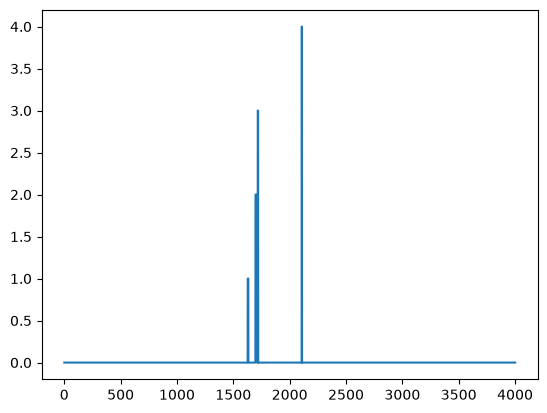

In [41]:
plt.plot(wind_speed_data["group_no"])

In [42]:
LLJ_1=wind_speed_data[wind_speed_data["group_no"]==1]
LLJ_2=wind_speed_data[wind_speed_data["group_no"]==2]
LLJ_3=wind_speed_data[wind_speed_data["group_no"]==3]
LLJ_4=wind_speed_data[wind_speed_data["group_no"]==4]

In [43]:
LLJ_1

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
1628,2025-02-12 09:50:00,3.89,4.48,4.59,4.15,3.49,2.90,2.52,2.36,2.34,2.44,2.62,2.79,2.94,3.11,True,80,True,1
1629,2025-02-12 10:00:00,3.52,3.83,4.07,4.25,4.02,3.44,2.84,2.35,2.16,2.09,2.23,2.42,2.51,2.61,True,100,True,1
1630,2025-02-12 10:10:00,3.22,3.62,4.04,4.22,4.05,3.64,3.12,2.52,2.11,2.01,2.16,2.37,2.47,2.63,True,100,True,1
1631,2025-02-12 10:20:00,3.81,4.08,4.12,4.31,4.38,4.22,3.76,3.25,2.72,2.36,2.32,2.30,2.25,2.29,True,120,True,1
1632,2025-02-12 10:30:00,3.32,3.71,4.12,4.41,4.42,3.98,3.48,3.02,2.60,2.28,2.13,1.98,2.00,2.02,True,120,True,1
1633,2025-02-12 10:40:00,3.07,3.12,3.33,3.44,3.53,3.61,3.57,3.45,3.24,2.88,2.47,1.91,1.59,1.50,True,140,True,1


LLJ=110.0


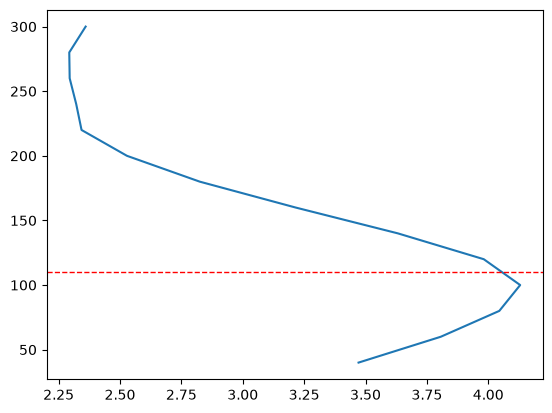

In [60]:
LLJ_1_mean=LLJ_1.iloc[:,1:15].mean()
plt.plot(LLJ_1_mean,alt)
y=LLJ_1["LLJ_Height"].mean()
plt.axhline(y, color='red', linestyle='dashed', linewidth=1, label='Mean Height')
print(f"LLJ={y}")

In [49]:
LLJ_2

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
1697,2025-02-12 21:20:00,2.82,3.29,3.71,4.20,4.62,4.80,4.97,5.05,4.79,4.28,3.74,3.24,3.12,2.82,True,180,True,2
1698,2025-02-12 21:30:00,3.08,3.67,4.26,4.88,5.16,5.15,5.05,4.58,3.87,3.20,2.58,2.33,2.50,3.36,True,120,True,2
1699,2025-02-12 21:40:00,3.14,3.92,4.49,5.06,5.38,5.28,4.83,4.12,3.45,2.79,2.41,2.37,2.41,NaN,True,120,True,2
1700,2025-02-12 21:50:00,3.06,3.96,4.53,5.08,5.40,5.30,4.99,4.44,3.74,3.05,2.67,2.53,2.47,2.73,True,120,True,2
1701,2025-02-12 22:00:00,2.70,3.32,3.89,4.35,4.76,5.12,5.40,5.36,5.07,4.76,4.25,3.66,3.17,2.90,True,160,True,2
1702,2025-02-12 22:10:00,2.31,2.81,3.53,3.97,4.30,4.86,5.33,5.63,5.69,5.35,4.60,3.71,2.88,2.55,True,200,True,2
1703,2025-02-12 22:20:00,2.39,3.02,3.57,4.00,4.61,5.39,6.34,6.97,7.06,6.76,6.02,5.07,4.02,3.16,True,200,True,2
1704,2025-02-12 22:30:00,2.22,2.87,3.55,4.18,4.94,5.89,6.79,7.40,7.44,7.02,6.31,5.37,4.35,3.48,True,200,True,2
1705,2025-02-12 22:40:00,2.56,3.23,3.89,4.62,5.38,6.11,6.71,7.02,7.23,7.01,6.52,5.91,5.23,4.36,True,200,True,2
1706,2025-02-12 22:50:00,3.07,4.11,4.91,5.59,6.04,6.49,6.86,6.92,6.76,6.28,5.73,5.13,4.44,3.76,True,180,True,2


In [1]:
LLJ_2_mean=LLJ_2.iloc[:,1:15].mean()
plt.plot(LLJ_2_mean,alt)
y=LLJ_2["LLJ_Height"].mean()
plt.axhline(y, color='red', linestyle='dashed', linewidth=1, label='Mean Height')
print(f"LLJ={y}")

NameError: name 'LLJ_2' is not defined

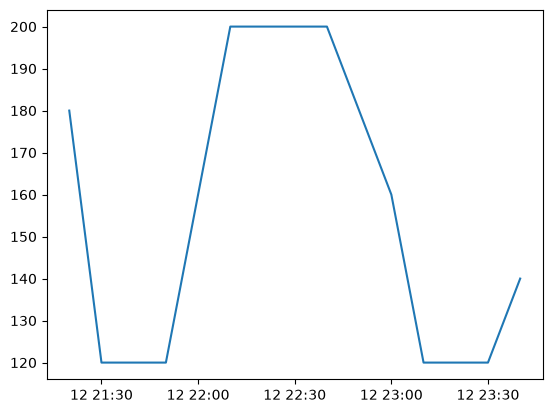

In [50]:
plt.plot(LLJ_2["Timestamp (end of interval)"],LLJ_2["LLJ_Height"])

In [64]:
LLJ_3

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
1717,2025-02-13 00:40:00,2.86,3.34,3.83,4.29,4.40,4.16,3.72,3.14,2.68,2.38,2.50,3.23,NaN,NaN,True,120,True,3
1718,2025-02-13 00:50:00,2.22,3.06,3.64,3.61,3.31,2.88,2.21,1.53,1.31,1.53,2.03,2.38,NaN,NaN,True,80,True,3
1719,2025-02-13 01:00:00,3.21,4.17,5.05,5.42,5.03,4.17,3.14,2.27,1.56,1.16,1.51,NaN,NaN,NaN,True,100,True,3
1720,2025-02-13 01:10:00,4.27,5.31,6.29,7.01,7.22,6.82,6.15,5.40,4.54,3.73,2.86,NaN,NaN,NaN,True,120,True,3


LLJ=105.0


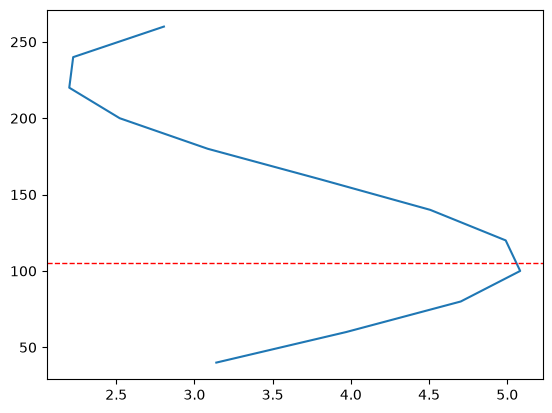

In [62]:
LLJ_3_mean=LLJ_3.iloc[:,1:15].mean()
plt.plot(LLJ_3_mean,alt)
y=LLJ_3["LLJ_Height"].mean()
plt.axhline(y, color='red', linestyle='dashed', linewidth=1, label='Mean Height')
print(f"LLJ={y}")

LLJ=66.66666666666667


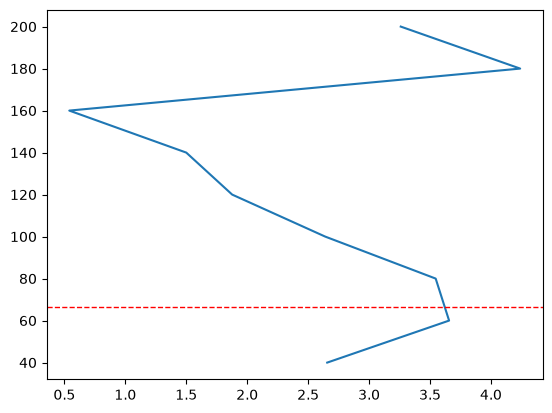

In [63]:
LLJ_4_mean=LLJ_4.iloc[:,1:15].mean()
plt.plot(LLJ_4_mean,alt)
y=LLJ_4["LLJ_Height"].mean()
plt.axhline(y, color='red', linestyle='dashed', linewidth=1, label='Mean Height')
print(f"LLJ={y}")

In [48]:
LLJ_4

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
2107,2025-02-15 18:50:00,2.47,3.53,3.03,2.39,1.45,1.23,0.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,60,True,4
2108,2025-02-15 19:00:00,2.54,3.54,3.95,2.91,2.14,1.77,NaN,4.24,NaN,NaN,NaN,NaN,NaN,NaN,True,80,True,4
2109,2025-02-15 19:10:00,2.96,3.90,3.66,2.62,2.04,1.50,0.43,NaN,3.26,NaN,NaN,NaN,NaN,NaN,True,60,True,4


In [30]:
LLJ_true=wind_speed_data[wind_speed_data["LLJ_Status"]=="True"]
LLJ_true

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s),LLJ_Status,LLJ_Height,renzoku,group_no
141,2025-02-02 00:00:00,3.31,3.92,4.04,3.89,3.47,2.96,2.39,1.96,1.95,2.05,2.17,2.14,2.17,1.97,True,80,False,0
378,2025-02-03 15:30:00,2.57,2.79,2.79,2.63,2.36,2.14,1.95,1.75,1.59,1.29,0.93,0.70,1.17,1.62,True,60,False,0
413,2025-02-03 21:20:00,3.03,3.77,4.51,5.16,5.75,6.34,6.68,6.86,6.79,6.47,6.06,5.54,5.15,4.75,True,180,False,0
414,2025-02-03 21:30:00,4.92,5.78,6.39,6.83,7.18,7.29,7.11,6.87,6.64,6.44,6.11,5.81,5.53,5.26,True,140,False,0
982,2025-02-07 21:10:00,2.28,2.61,2.68,2.43,2.01,1.75,1.62,1.49,1.41,1.24,0.95,0.67,0.41,0.67,True,80,False,0
986,2025-02-07 21:50:00,2.19,2.97,3.63,3.68,3.15,2.64,2.13,1.69,1.49,1.48,1.61,1.72,1.74,1.57,True,100,False,0
1178,2025-02-09 06:50:00,6.23,6.39,6.12,5.49,5.58,5.53,5.36,5.87,6.21,6.81,6.64,7.62,11.96,7.18,True,280,False,0
1320,2025-02-10 06:30:00,3.70,4.01,3.95,3.83,3.51,3.16,2.86,2.58,2.54,2.36,2.26,2.13,1.95,2.25,True,60,False,0
1508,2025-02-11 13:50:00,11.38,12.51,13.25,13.97,14.81,15.10,15.42,15.84,16.26,17.81,18.41,19.55,20.84,15.56,True,280,False,0
1510,2025-02-11 14:10:00,9.55,10.44,10.94,11.37,11.52,11.94,12.21,12.61,12.72,12.70,12.66,11.14,12.86,9.05,True,280,False,0


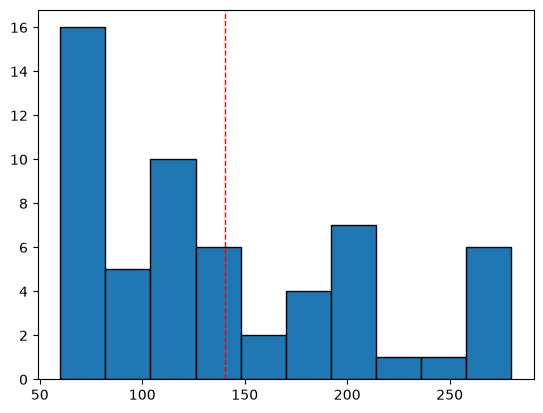

In [35]:
plt.hist(LLJ_true["LLJ_Height"], edgecolor="black")
plt.axvline(LLJ_true["LLJ_Height"].mean(), color='red', linestyle='dashed', linewidth=1, label='Mean Height')

In [36]:
print("Mean LLJ Height:", LLJ_true["LLJ_Height"].mean())

Mean LLJ Height: 140.3448275862069
